# Ordenación por montículo (heap sort)

Un montículo máximo es un árbol binario completo, guardado en una lista (hijos de $i$ en $2i+1$ y $2i+2$), donde cada padre es mayor o igual que sus hijos. Heap sort construye el montículo y extrae repetidamente el máximo al final de la lista. Cuesta $O(n \log n)$ siempre y no usa memoria extra.

## 1. Heap sort

Implementar `hundir` (restaura la propiedad de montículo bajando un nodo) y heap sort en el sitio.

In [1]:
import random

def hundir(l, i, n):
    while True:
        mayor = i
        for hijo in (2 * i + 1, 2 * i + 2):
            if hijo < n and l[hijo] > l[mayor]:
                mayor = hijo
        if mayor == i:
            return
        l[i], l[mayor] = l[mayor], l[i]
        i = mayor

def heap_sort(l):
    n = len(l)
    # construye el montículo desde el último padre
    for i in range(n // 2 - 1, -1, -1):
        hundir(l, i, n)
    for fin in range(n - 1, 0, -1):
        l[0], l[fin] = l[fin], l[0]
        hundir(l, 0, fin)
    return l

for _ in range(200):
    datos = random.choices(range(100), k=random.randint(0, 50))
    assert heap_sort(datos[:]) == sorted(datos)
print(heap_sort([12, 11, 13, 5, 6, 7]))

[5, 6, 7, 11, 12, 13]


## 2. Con `heapq`

La biblioteca estándar ofrece un montículo mínimo en `heapq`. Ordenar con él y obtener los 3 mayores con `nlargest`.

In [2]:
import heapq

def heap_sort_heapq(lista):
    monticulo = lista[:]
    heapq.heapify(monticulo)
    return [heapq.heappop(monticulo) for _ in range(len(monticulo))]

datos = [12, 11, 13, 5, 6, 7]
print(heap_sort_heapq(datos), heapq.nlargest(3, datos))

[5, 6, 7, 11, 12, 13] [13, 12, 11]


## 3. Estabilidad

Heap sort no es estable: al llevar el máximo al final puede adelantar a un elemento igual que estaba antes. Comprobarlo ordenando alumnos por nota (basta con dos alumnos con la misma nota) y hacerlo estable decorando cada elemento con su posición original, `(clave, índice)`, para desempatar.

In [3]:
def hundir_clave(l, i, n, clave):
    while True:
        mayor = i
        for hijo in (2 * i + 1, 2 * i + 2):
            if hijo < n and clave(l[hijo]) > clave(l[mayor]):
                mayor = hijo
        if mayor == i:
            return
        l[i], l[mayor] = l[mayor], l[i]
        i = mayor

def heap_sort_clave(lista, clave):
    l, n = lista[:], len(lista)
    for i in range(n // 2 - 1, -1, -1):
        hundir_clave(l, i, n, clave)
    for fin in range(n - 1, 0, -1):
        l[0], l[fin] = l[fin], l[0]
        hundir_clave(l, 0, fin, clave)
    return l

def heap_sort_estable(lista, clave):
    decorada = [((clave(x), i), x) for i, x in enumerate(lista)]
    return [x for _, x in heap_sort_clave(decorada, lambda par: par[0])]

def nota(alumno):
    return alumno[1]

print(heap_sort_clave([("Ana", 7), ("Eva", 7)], nota))
alumnos = [("Ana", 7), ("Luis", 5), ("Eva", 7), ("Pau", 10), ("Iker", 5)]
print("Heap sort:", heap_sort_clave(alumnos, nota))
print("Estable:  ", heap_sort_estable(alumnos, nota))
assert heap_sort_clave(alumnos, nota) != sorted(alumnos, key=nota)

random.seed(3)
for _ in range(300):
    datos = [(random.randint(0, 5), i) for i in range(random.randint(0, 30))]
    assert heap_sort_estable(datos, lambda r: r[0]) == sorted(datos, key=lambda r: r[0])

[('Eva', 7), ('Ana', 7)]
Heap sort: [('Iker', 5), ('Luis', 5), ('Eva', 7), ('Ana', 7), ('Pau', 10)]
Estable:   [('Luis', 5), ('Iker', 5), ('Ana', 7), ('Eva', 7), ('Pau', 10)]


## 4. Construir el montículo en $O(n)$

Construir el montículo hundiendo los padres de abajo arriba cuesta $O(n)$: como mucho $2n$ comparaciones, porque la mayoría de nodos están cerca de las hojas y bajan poco. Insertar los elementos uno a uno y hacerlos flotar hacia la raíz cuesta $O(n \log n)$ en el peor caso (lista creciente, cada nuevo elemento sube hasta arriba). Contar las comparaciones de las dos construcciones y dibujarlas por elemento.

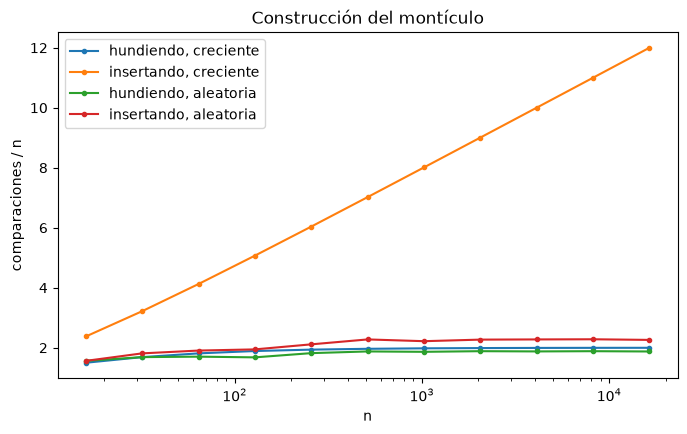

In [4]:
import matplotlib.pyplot as plt

def hundir_contando(l, i, n):
    comparaciones = 0
    while True:
        mayor = i
        for hijo in (2 * i + 1, 2 * i + 2):
            if hijo < n:
                comparaciones += 1
                if l[hijo] > l[mayor]:
                    mayor = hijo
        if mayor == i:
            return comparaciones
        l[i], l[mayor] = l[mayor], l[i]
        i = mayor

def construye_hundiendo(lista):
    l = lista[:]
    comparaciones = sum(hundir_contando(l, i, len(l)) for i in range(len(l) // 2 - 1, -1, -1))
    return l, comparaciones

def construye_insertando(lista):
    l, comparaciones = [], 0
    for x in lista:
        l.append(x)
        i = len(l) - 1
        while i > 0:
            padre = (i - 1) // 2
            comparaciones += 1
            if l[padre] >= l[i]:
                break
            l[padre], l[i] = l[i], l[padre]
            i = padre
    return l, comparaciones

def es_monticulo(l):
    return all(l[(i - 1) // 2] >= l[i] for i in range(1, len(l)))

random.seed(4)
tamanos = [2**k for k in range(4, 15)]
resultados = {"hundiendo, creciente": [], "insertando, creciente": [], "hundiendo, aleatoria": [], "insertando, aleatoria": []}
for n in tamanos:
    for entrada, datos in (("creciente", list(range(n))), ("aleatoria", random.sample(range(n), n))):
        for nombre, construye in (("hundiendo", construye_hundiendo), ("insertando", construye_insertando)):
            l, c = construye(datos)
            assert es_monticulo(l)
            if nombre == "hundiendo":
                assert c <= 2 * n
            resultados[f"{nombre}, {entrada}"].append(c / n)

fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, valores in resultados.items():
    ax.plot(tamanos, valores, marker=".", label=nombre)
ax.set(xscale="log", xlabel="n", ylabel="comparaciones / n", title="Construcción del montículo")
ax.legend()
plt.show()